In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as sp


In [2]:
raw = pd.read_csv(r'D:\Python_Ironhack_precourse\exercises\Wk3\lab-eda-univariate\amz_uk_price_prediction_dataset.csv\amz_uk_price_prediction_dataset.csv')

raw_copy = raw.copy()



To find the bestselling products per category in Amazon UK, I would find the best sellers for each category and sort them in descending order.

In [3]:
raw_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


Based on the information of the dataset, category is an object and best seller is a boolean. I'll be anaylsing them in the following steps.

In [4]:
#Crosstab analysis
best_sellers = pd.crosstab(
    raw_copy["category"],
    raw_copy['isBestSeller']
)
best_sellers = best_sellers.reindex(columns=[False, True])
#Ratio: True/False
best_sellers["Ratio"] = (
    best_sellers[True]
    .div(best_sellers[False].replace(0, np.nan))
    .round(5)
)
#best_sellers['Ratio'] = (best_sellers.iloc[:,1]/best_sellers.iloc[:,0]).round(5)
best_sellers

isBestSeller,False,True,Ratio
category,,,
3D Printers,247,1,0.00405
3D Printing & Scanning,4065,2,0.00049
Abrasive & Finishing Products,245,5,0.02041
Action Cameras,1696,1,0.00059
Adapters,251,3,0.01195
...,...,...,...
Wind Instruments,243,7,0.02881
Window Treatments,234,5,0.02137
Women,17559,213,0.01213


Sorted by count instances:

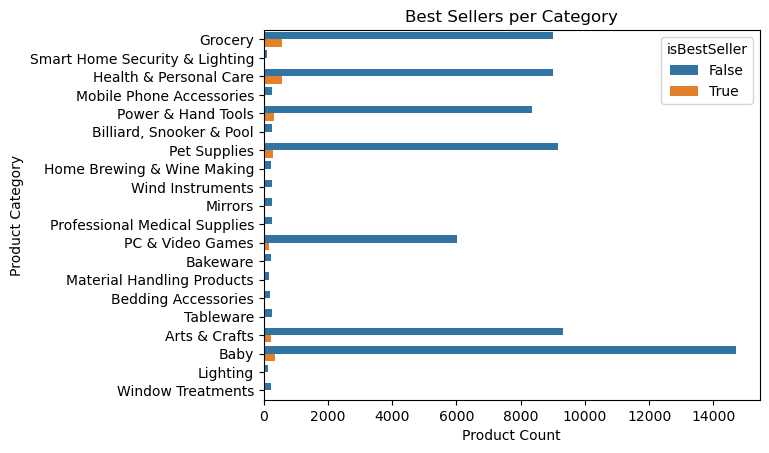

In [5]:

sorted_ratio = best_sellers.sort_values('Ratio', ascending=False).head(20).index
sns.countplot(data=raw_copy, 
              y = 'category',
              hue = 'isBestSeller',
                order = sorted_ratio
            )
plt.xlabel('Product Count')
plt.ylabel('Product Category')
plt.title("Best Sellers per Category")  
plt.show()


Sorted by the best-seller ratio :

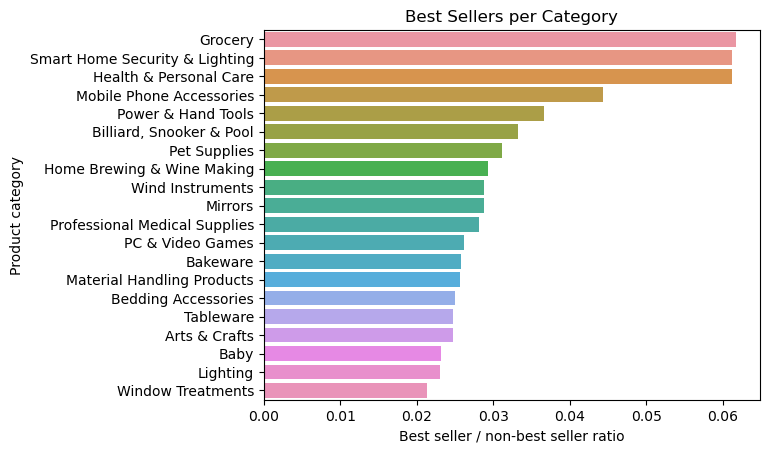

In [6]:
plot_data = (
    best_sellers
    .sort_values("Ratio", ascending=False)
    .head(20)
    .reset_index()
)

sns.barplot(
    data=plot_data,
    x="Ratio",
    y="category",
    orient="h"
)

plt.title("Best Sellers per Category")
plt.xlabel("Best seller / non-best seller ratio")
plt.ylabel("Product category")
plt.show()

A Chi-square test will be applied to the analysis and determine whether best-sellers are independent of product category or not.

In [7]:
#Chi-square test:

chi2, p, dof, expected = sp.chi2_contingency(best_sellers)
print(f"Chi2 stat: {chi2:.4f}")
print(f"P-Value: {p:.4f}")
print(f"DOF: {dof}")
print(f"Expected frequencies: {expected.round(2)}")

Chi2 stat: 36691.4941
P-Value: 0.0000
DOF: 590
Expected frequencies: [[2.4719000e+02 8.1000000e-01 0.0000000e+00]
 [4.0537200e+03 1.3280000e+01 0.0000000e+00]
 [2.4920000e+02 8.2000000e-01 0.0000000e+00]
 [1.6914600e+03 5.5400000e+00 0.0000000e+00]
 [2.5318000e+02 8.3000000e-01 0.0000000e+00]
 [8.5021500e+03 2.7860000e+01 1.0000000e-02]
 [1.0666000e+02 3.5000000e-01 0.0000000e+00]
 [2.5718000e+02 8.4000000e-01 0.0000000e+00]
 [9.5178300e+03 3.1180000e+01 1.0000000e-02]
 [1.5000860e+04 4.9150000e+01 1.0000000e-02]
 [9.3254400e+03 3.0550000e+01 1.0000000e-02]
 [2.3825000e+02 7.8000000e-01 0.0000000e+00]
 [3.2294200e+03 1.0580000e+01 0.0000000e+00]
 [9.4470400e+03 3.0950000e+01 1.0000000e-02]
 [6.6880800e+03 2.1910000e+01 1.0000000e-02]
 [5.2628000e+02 1.7200000e+00 0.0000000e+00]
 [1.9029640e+04 6.2350000e+01 1.0000000e-02]
 [2.7719200e+03 9.0800000e+00 0.0000000e+00]
 [2.5318000e+02 8.3000000e-01 0.0000000e+00]
 [4.0469000e+02 1.3300000e+00 0.0000000e+00]
 [1.9248940e+04 6.3070000e+01 1

The Chi2 value indicates a high dependency found between the category and being a best-seller. It is further supported by the fact that P-value is less than 0.05, hence the null-hypothesis of them being independent of each other is rejected.

In [8]:
#Cramer's von mises
def cramers_v (best_sellers):
    x2 = sp.chi2_contingency(best_sellers, correction=False)[0]
    phi2 = x2/best_sellers.sum().sum()
    n_rows, n_cols = best_sellers.shape
    return (phi2/min(n_cols -1, n_rows -1))**0.5
    
cramerv = cramers_v(best_sellers)
print(cramerv)


0.08664588568222313


In [9]:
#cramer's von mises method with scipy
cramerv = cramers_v(best_sellers)
cramerv

0.08664588568222313

The Cramer's von mises test show that the degree of association is high and that the p-value is low. This shows that the best sellers are related to the categories they are in.

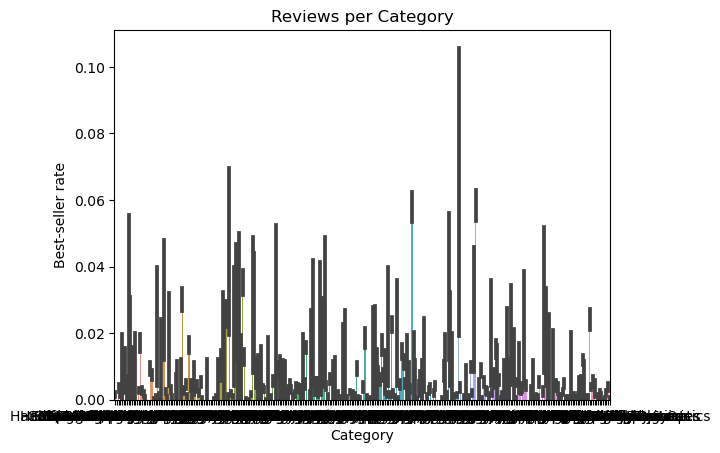

In [10]:
#Visual

sns.barplot(
    x = raw_copy['category'],
    y = raw_copy['isBestSeller']
)

plt.ylabel("Best-seller rate")
plt.xlabel("Category")
plt.title("Reviews per Category")
plt.show()

Now, the product prices and their ratings will be analysed cross various categories and brands.

In [11]:
#clean up outliers:

def outlier_cleanup(raw_copy):
    price = pd.to_numeric(raw_copy["price"], errors="coerce")
    
    IQR = sp.iqr(price)

    lowerbound = price.quantile(0.25) - 1.5*IQR
    upperbound = price.quantile(0.75) + 1.5*IQR

    return  price.between(lowerbound, upperbound)

clean_copy = outlier_cleanup(raw_copy)
clean_copy

0          True
1          True
2          True
3          True
4          True
           ... 
2443646    True
2443647    True
2443648    True
2443649    True
2443650    True
Name: price, Length: 2443651, dtype: bool

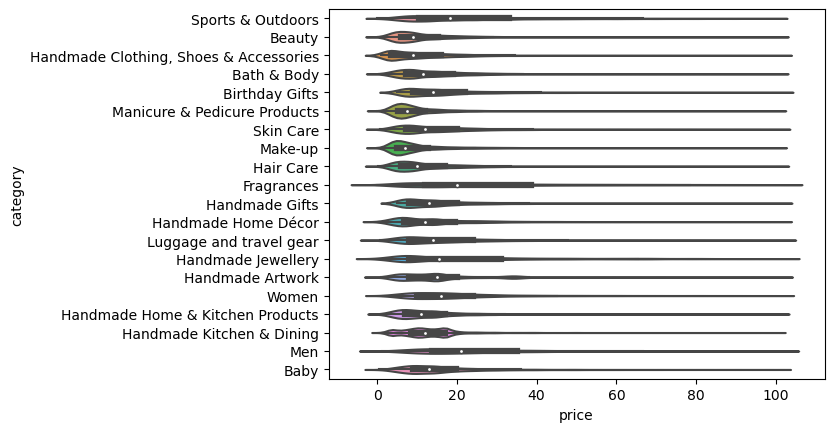

In [12]:
top_categories = (
    raw_copy["category"]
    .value_counts(ascending=False)
    .head(20)
    .index
)

sns.violinplot(
    data=raw_copy.loc[clean_copy],
    x="price",
    y="category",
    order=top_categories
)
plt.show()

In [13]:
#highest median price
def max_median_price(clean_copy):
    median_by_category = (
        raw_copy.loc[clean_copy]
        .groupby("category")["price"]
        .median()
        .sort_values(ascending=False)
        .head(1)
    )

    price = median_by_category
    return price

price = max_median_price(clean_copy)
print(price)


category
Desktop PCs    74.0
Name: price, dtype: float64


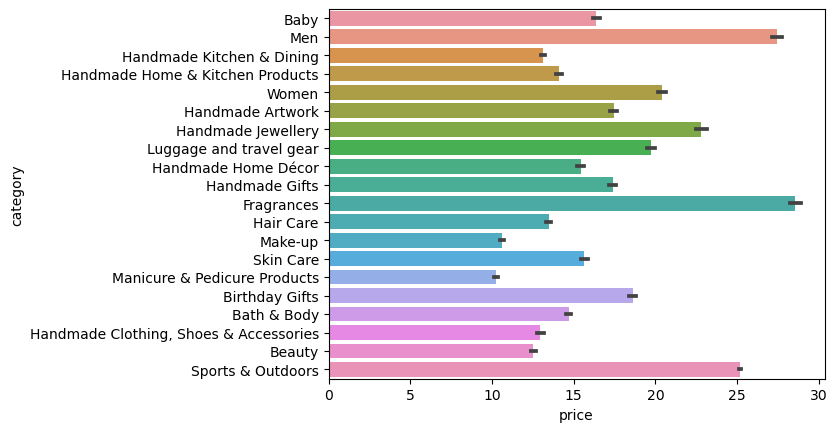

In [14]:
#Bar chart

sns.barplot(data=raw_copy.loc[clean_copy],
            x = 'price',
            y='category',
            order=top_categories[::-1])
plt.show()

In [15]:
#highest median price
def max_mean_price(clean_copy):
    mean_by_category = (
        raw_copy.loc[clean_copy]
        .groupby("category")["price"]
        .mean()
        .sort_values(ascending=False)
        .head(1)
    )

    price = mean_by_category
    return price

price = max_mean_price(clean_copy)
print(price)


category
Motherboards    68.772432
Name: price, dtype: float64


<AxesSubplot:xlabel='price', ylabel='category'>

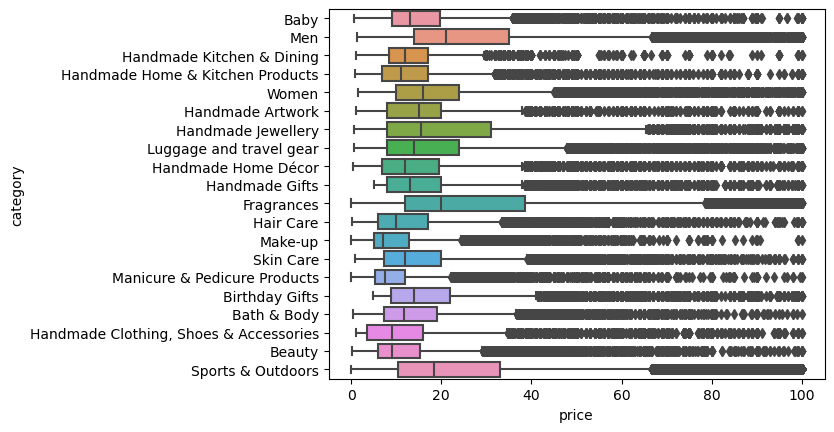

In [16]:
#Box plot

sns.boxplot(
    data=raw_copy.loc[clean_copy],
    x='price',
    y='category',
    order = top_categories[::-1]
)

In [27]:
# Highest median rating

def max_median_rating(clean_copy):
    median_by_rating = (
        raw_copy.loc[clean_copy]
        .groupby("category")["stars"]
        .median()
        .sort_values(ascending=False)
        .head(1)
    )

    rating = median_by_rating
    return rating

rating = max_median_rating(clean_copy)
print(rating)

category
Computer Memory    4.7
Name: stars, dtype: float64


Now, the product prices and their ratings will be studied; particularly how the ratings correlate with prices such that a coefficient of correlation should be determined.

In [18]:
#Determining the correlation coefficient:

product_rating = pd.crosstab(
    raw_copy["price"],
    raw_copy['stars']
)
product_rating.corr()

stars,0.0,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,...,4.1,4.2,4.3,4.4,4.5,4.6,4.7,4.8,4.9,5.0
stars,,,,,,,,,,,,,,,,,,,,,
0.0,1.000000,0.896182,0.118880,0.313351,0.498637,0.641624,0.740620,0.501890,0.575310,0.692519,...,0.901012,0.904110,0.904835,0.905909,0.907870,0.910615,0.914133,0.902067,0.888512,0.898744
1.0,0.896182,1.000000,0.179742,0.355768,0.476695,0.653555,0.811776,0.553725,0.626749,0.666469,...,0.969045,0.967719,0.965512,0.967753,0.967978,0.964625,0.949066,0.935305,0.920602,0.960225
1.1,0.118880,0.179742,1.000000,0.115391,-0.000142,0.107489,0.109281,0.037325,0.129992,0.074712,...,0.142195,0.151769,0.138295,0.144402,0.146800,0.133450,0.118643,0.114574,0.109070,0.148444
1.2,0.313351,0.355768,0.115391,1.000000,0.173771,0.273065,0.275808,0.155472,0.247539,0.233058,...,0.345801,0.344261,0.349302,0.349538,0.355191,0.347004,0.326390,0.308356,0.299825,0.339080
1.3,0.498637,0.476695,-0.000142,0.173771,1.000000,0.448490,0.452044,0.299116,0.274053,0.477488,...,0.478874,0.490285,0.482461,0.486812,0.486274,0.491047,0.484710,0.470388,0.461952,0.467477
1.4,0.641624,0.653555,0.107489,0.273065,0.448490,1.000000,0.578259,0.338338,0.391438,0.534044,...,0.656381,0.660115,0.658984,0.660607,0.661286,0.657057,0.650796,0.639910,0.638766,0.645358
1.5,0.740620,0.811776,0.109281,0.275808,0.452044,0.578259,1.000000,0.449567,0.470713,0.585893,...,0.810673,0.808099,0.803583,0.803618,0.806276,0.801607,0.784601,0.766793,0.758984,0.789984
1.6,0.501890,0.553725,0.037325,0.155472,0.299116,0.338338,0.449567,1.000000,0.383583,0.372734,...,0.532685,0.531564,0.527607,0.535665,0.535115,0.537245,0.529331,0.519888,0.506632,0.543140
1.7,0.575310,0.626749,0.129992,0.247539,0.274053,0.391438,0.470713,0.383583,1.000000,0.437744,...,0.632126,0.633943,0.630087,0.634215,0.629353,0.619632,0.599835,0.601171,0.578572,0.622082


The table of coefficients tell us the frequency patterns of different ratings per category and their variance across the groups. Notice that it creates a diagonal matrix with 1 in the diagonals? 


In [19]:
#as general:
coeff_corr_gen = raw_copy[["price", "stars"]].corr()
print(f"Coefficient of correlation: {coeff_corr_gen}")

Coefficient of correlation:           price     stars
price  1.000000 -0.124907
stars -0.124907  1.000000


The correlation between the price and ratings are in the negative. This means that there is an inverse relation between the two, but weak.

Price ∝ 1/Ratings

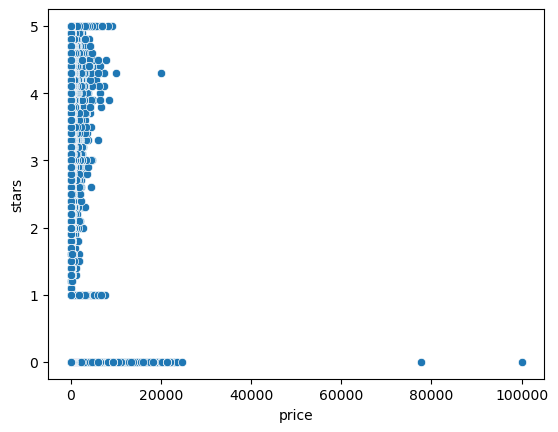

In [20]:
#Visuals:

sns.scatterplot(
    data = raw_copy.loc[clean_copy],
    x = raw_copy['price'],
    y = raw_copy['stars'],
)
plt.show()

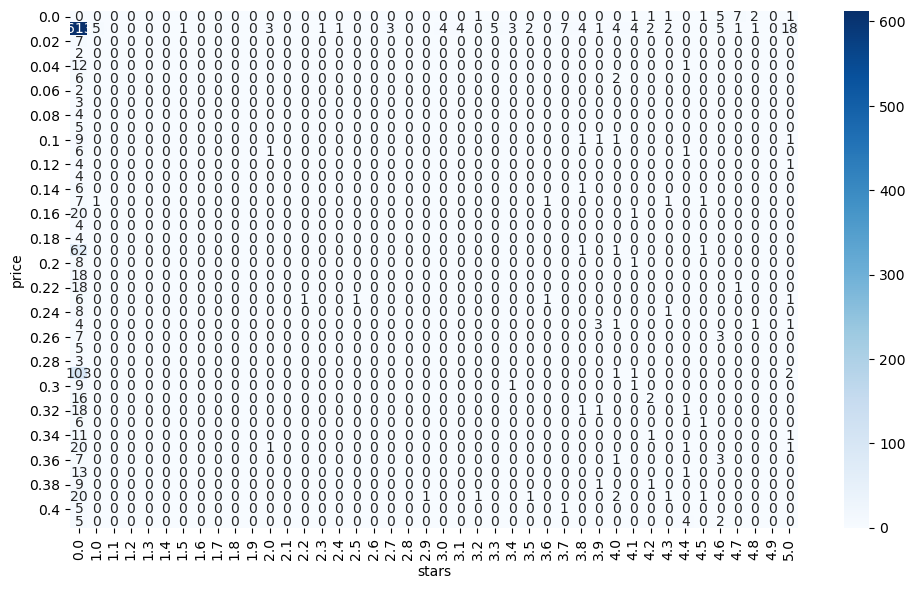

In [ ]:
#Heatmap. I can't render the full heatmap because it kept on crashing my laptop.

small_table = product_rating.iloc[:42, :42]

plt.figure(figsize=(10, 6))
sns.heatmap(
    small_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.tight_layout()
plt.show()
plt.close()

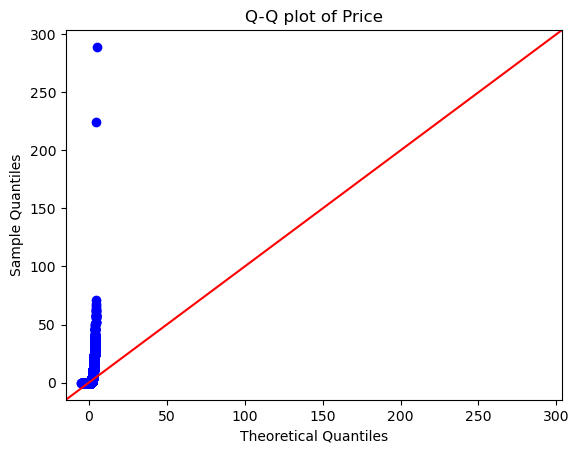

In [26]:
#qqplot
import statsmodels.api as sm

sm.qqplot(
    data=raw_copy['price'].dropna(),
    line='45',
    fit=True
)
plt.title("Q-Q plot of Price")
plt.show()